
# Impulso 8/20 us (modelo tipo Heidler)

Este notebook mostra um modelo matematico simples e pratico para representar uma corrente de surto do tipo **8/20 us** (frente rapida e cauda mais lenta), usando uma funcao do tipo **Heidler**, muito usada em modelagem de impulsos.

## Modelo

\[
i(t)=I_p\;\frac{1}{k}\;\frac{\left(\frac{t}{\tau_1}\right)^n}{1+\left(\frac{t}{\tau_1}\right)^n}\;e^{-t/\tau_2}
\]

- \(I_p\): corrente de pico (A)  
- \(n\): "agudeza" da frente  
- \(\tau_1\): controla a subida (us)  
- \(\tau_2\): controla a cauda (us)  
- \(k\): fator de normalizacao para garantir que o pico seja exatamente \(I_p\)

## Escolha numerica (conveniente)

- \(n=3\)  
- \(\tau_1 = 5.0\,us\)  
- \(\tau_2 = 13.5\,us\)

Com esses valores, a curva fica bem proxima de um **8/20 us**: pico em torno de **8 us** e valor em **20 us** em torno de **50% do pico**.


In [1]:
import numpy as np
import matplotlib.pyplot as plt



## Implementacao

A estrategia abaixo calcula o fator **k** automaticamente:
1. Define a funcao sem normalizacao (assumindo \(I_p=1\));
2. Encontra o valor maximo numericamente;
3. Define \(k\) como esse maximo (assim, o pico normalizado vira exatamente \(I_p\)).


In [2]:

def heidler_base(t_us: np.ndarray, n: float, tau1_us: float, tau2_us: float) -> np.ndarray:
    '''
    Heidler pulse without peak normalization (Ip assumed 1).
    t_us: time in microseconds.
    Returns a dimensionless waveform (peak != 1 in general).
    '''
    t_us = np.asarray(t_us, dtype=float)
    x = t_us / tau1_us
    frac = (x ** n) / (1.0 + (x ** n))
    y = frac * np.exp(-t_us / tau2_us)
    return y


def compute_k(n: float, tau1_us: float, tau2_us: float, tmax_us: float = 200.0, dt_us: float = 0.01) -> float:
    '''
    Compute k as the numerical peak of the unnormalized Heidler waveform.
    '''
    t = np.arange(0.0, tmax_us + dt_us, dt_us)
    y = heidler_base(t, n=n, tau1_us=tau1_us, tau2_us=tau2_us)
    k = float(np.max(y))
    return k


def heidler_pulse(t_us: np.ndarray, Ip_A: float, n: float, tau1_us: float, tau2_us: float, k: float) -> np.ndarray:
    '''
    Peak-normalized Heidler pulse.
    '''
    y = heidler_base(t_us, n=n, tau1_us=tau1_us, tau2_us=tau2_us)
    i = Ip_A * (1.0 / k) * y
    return i



## Parametros e checagem (pico ~ 8 us, meia-corrente ~ 20 us)

A seguir, definimos:
- \(I_p = 10\,kA\) (exemplo)
- \(n=3\), \(\tau_1=5.0\,us\), \(\tau_2=13.5\,us\)


In [3]:
Ip_A = 10_000.0  # 10 kA
n = 3.0
tau1_us = 5.0
tau2_us = 13.5

k = compute_k(n=n, tau1_us=tau1_us, tau2_us=tau2_us, tmax_us=200.0, dt_us=0.001)
k


0.44439838388958147

In [4]:
t = np.arange(0.0, 200.0 + 0.02, 0.02)  # us
i = heidler_pulse(t, Ip_A=Ip_A, n=n, tau1_us=tau1_us, tau2_us=tau2_us, k=k)

idx_peak = int(np.argmax(i))
t_peak_us = float(t[idx_peak])
i_peak_A = float(i[idx_peak])

t20 = 20.0
i20 = float(np.interp(t20, t, i))

t_peak_us, i_peak_A, i20 / i_peak_A


(7.98, 9999.996769973723, 0.5036108222952382)


A saida acima retorna:
- \(t_{pico}\) em us,
- \(i_{pico}\) em A,
- razao \(i(20\,us)/i_{pico}\).

Em geral, deve ficar proximo de:
- \(t_{pico}\approx 8\,us\)
- \(i(20\,us)\approx 0.5\,i_{pico}\)


## Grafico

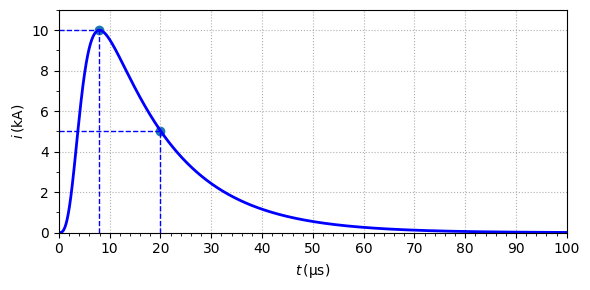

In [35]:
from matplotlib.lines import lineStyles
plt.figure(figsize=(6,3))
plt.plot(t, i / 1000.0, color='blue', lw=2)  # kA
plt.xlabel(r"$t \, \mathrm{(\mu s)}$")
plt.ylabel(r"$i \, \mathrm{(kA)}$")
plt.grid(ls=":")
# plt.title("Impulso tipo 8/20 us (modelo Heidler)")

plt.plot([0, t_peak_us],
         [i_peak_A / 1000.0, i_peak_A / 1000.0],
         linewidth=1.0, ls='--', color='blue')

plt.plot([t_peak_us, t_peak_us],
         [0, i_peak_A / 1000.0],
         linewidth=1.0, ls='--', color='blue')

plt.plot([0, 20],
         [0.5*i_peak_A / 1000.0, 0.5*i_peak_A / 1000.0],
         linewidth=1.0, ls='--', color='blue')

plt.plot([20, 20],
         [0, 0.5*i_peak_A / 1000.0],
         linewidth=1.0, ls='--', color='blue')

plt.scatter([t_peak_us, 20],
            [i_peak_A / 1000.0, 0.5*i_peak_A / 1000.0])

plt.xlim(0, 100)
plt.ylim(0, 11)
ax = plt.gca()

from matplotlib.ticker import MultipleLocator
ax = plt.gca()
ax.xaxis.set_major_locator(MultipleLocator(10))   # escala principal
ax.xaxis.set_minor_locator(MultipleLocator(2))    # escala secundaria

ax.yaxis.set_major_locator(MultipleLocator(2))
ax.yaxis.set_minor_locator(MultipleLocator(1))


plt.tight_layout()
plt.show()



## Exportar figura (opcional)

Se quiser salvar a figura em 300 dpi:


In [6]:
# Save at 300 dpi (optional)
# plt.figure()
# plt.plot(t, i / 1000.0)
# plt.xlabel("t (us)")
# plt.ylabel("i (kA)")
# plt.title("Impulso tipo 8/20 us (modelo Heidler)")
# plt.tight_layout()
# plt.savefig("impulso_8_20_heidler.png", dpi=300)
